# Tier 1 explicado: aprender a equilibrar CartPole

**Integrantes:** Harolt y compañero · Agentes Inteligentes · Project 01

Este cuaderno es la entrada principal para **entender el código, cambiar parámetros,
consultar resultados y ver el carrito**. Los algoritmos son nuestros y viven en
`agents/`, `envs/` y `experiments/`. Aquí se muestra su código real; no hay una segunda
implementación que pueda quedar desactualizada.

**En VS Code:** abrir la carpeta completa del proyecto → abrir este archivo →
**Seleccionar kernel → Entornos de Python → `.venv\Scripts\python.exe`**.
Si falta soporte, instalar las extensiones Python y Jupyter de Microsoft y ejecutar
en la terminal `.\.venv\Scripts\python.exe -m pip install -r requirements-notebook.txt`.

Ejecutar las celdas **en orden** con Shift+Enter. “Ejecutar todo” carga ejemplos y
resultados guardados: el entrenamiento largo y la animación se activan expresamente.

## Recorrido
1. Preparación y problema · 2. Parámetros · 3. Q-learning · 4. DQN y memoria
5. Entrenamiento y evaluación · 6. Resultados · 7. Carrito · 8. Reproducción y defensa.

In [1]:
from pathlib import Path
import sys
import json
import copy
import csv
import numpy as np
import torch
import gymnasium as gym
from IPython.display import display, Markdown, Image

# Funciona abriendo el notebook desde la raíz o desde una subcarpeta del proyecto.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'agents/dqn.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Abre en VS Code la carpeta completa del proyecto.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from experiments.cuaderno_tier1 import (
    parametros, actual, codigo, resumen, entrenar, demostrar, evaluar_guardado,
)
from agents.tabular import QLearningAgent
from envs.discretizers import CartPoleDiscretizer
from agents.dqn import QNetwork, DQNAgent
from agents.replay import ReplayBuffer
from experiments.entrenar_tabular import train as entrenar_tabular, evaluate as evaluar_tabular
from experiments.entrenar_dqn import train as entrenar_dqn, evaluate_network

torch.set_num_threads(1)
torch.manual_seed(123)  # Solo ejemplos didácticos; cada entrenamiento fija su propia semilla.
print('Python:', sys.executable)
print('Gymnasium:', gym.__version__, '| PyTorch:', torch.__version__)
print('Proyecto:', ROOT)

Python: C:\Users\Harolt\Desktop\Universidad\Sem-02-2026\Agentes\Project 01\.venv\Scripts\python.exe
Gymnasium: 1.4.0 | PyTorch: 2.15.0+cpu
Proyecto: C:\Users\Harolt\Desktop\Universidad\Sem-02-2026\Agentes\Project 01


## 1. ¿Qué aprende el agente?

El carrito puede empujar a la **izquierda (0)** o **derecha (1)**. La observación tiene
cuatro números: **posición, velocidad, ángulo de la vara y velocidad angular**.
Recibe **+1 por paso**; el episodio termina si cae la vara o el carrito sale del rango.
A los 500 pasos se corta el episodio por tiempo.

El **objetivo del enunciado** es retorno medio ≥475 en 100 episodios. No equivale a
ver un único episodio de 500. Comprobamos también la especificación instalada:
el umbral declarado por la librería puede diferir del exigido por el docente.

In [2]:
env = gym.make('CartPole-v1')
try:
    observacion, info = env.reset(seed=123)
    print('Observación inicial:', observacion)
    print('Acciones:', env.action_space, '| Observaciones:', env.observation_space)
    print('Límite:', env.spec.max_episode_steps, '| Umbral declarado:', env.spec.reward_threshold)
    siguiente, recompensa, terminated, truncated, info = env.step(0)
    print('Después de mover a la izquierda:', siguiente)
    print('Recompensa:', recompensa, '| terminated:', terminated, '| truncated:', truncated)
finally:
    env.close()

Observación inicial: [ 0.01823519 -0.0446179  -0.02796401 -0.03156282]
Acciones: Discrete(2) | Observaciones: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Límite: 500 | Umbral declarado: 475.0
Después de mover a la izquierda: [ 0.01734283 -0.23932791 -0.02859527  0.25216764]
Recompensa: 1.0 | terminated: False | truncated: False


## 2. Parámetros que controlamos

La siguiente celda carga un diccionario **editable** de `configs/tier1_mejorado.json`.
Cambiarlo sí modifica los entrenamientos que lancemos más abajo; **no modifica modelos
ya guardados**. Sus parámetros originales se consultan en cada `config.json`.

| Parámetro | Significado |
|---|---|
| `steps` | Interacciones de entrenamiento por agente: mismo presupuesto para ambos métodos. |
| `seeds` | Repeticiones independientes; mínimo 3, 5 recomendadas para Tier 1. |
| `bins` | Tres granularidades de la tabla: 6, 10 y 20 intervalos por variable. |
| `eval_every` | Pasos entre evaluaciones de 10 episodios sin exploración. |
| `alpha` / `learning_rate` | Tamaño de los ajustes de la tabla / red neuronal. |
| `gamma` | Peso de recompensas futuras. |
| `epsilon_decay_steps` / `epsilon_end` | Duración del descenso de exploración / exploración final. |
| `velocity_limit` / `angular_velocity_limit` | Rangos de velocidad cubiertos por los intervalos tabulares. |
| `hidden_widths` | Número de neuronas de cada capa oculta. |
| `buffer_size` / `batch_size` | Experiencias conservadas / experiencias por ajuste. |
| `learning_starts` / `train_every` | Cuándo empezar a ajustar / pasos entre ajustes. |
| `target_sync_every` | Pasos entre copias de la red principal a la red objetivo. |
| `loss` | Cómo medimos el error: `mse` o `smooth_l1`. |

Las opciones de DQN y tabular pueden diferir: la comparación exige igual presupuesto,
entorno y protocolo de evaluación, no algoritmos con idénticos parámetros internos.

In [3]:
CONFIG = parametros()
# Ejemplos de edición (descomentar para un experimento nuevo):
# CONFIG['dqn']['learning_rate'] = 0.0001
# CONFIG['tabular']['alpha'] = 0.05
print(json.dumps(CONFIG, indent=2, ensure_ascii=False))

{
  "steps": 200000,
  "seeds": [
    42,
    43,
    44
  ],
  "bins": [
    6,
    10,
    20
  ],
  "eval_every": 10000,
  "dqn": {
    "learning_rate": 0.00025,
    "hidden_widths": [
      120,
      84
    ],
    "loss": "mse",
    "gamma": 0.99,
    "buffer_size": 10000,
    "batch_size": 128,
    "learning_starts": 10000,
    "train_every": 10,
    "target_sync_every": 500,
    "epsilon_decay_steps": 100000,
    "epsilon_end": 0.05
  },
  "tabular": {
    "alpha": 0.1,
    "gamma": 0.99,
    "velocity_limit": 0.75,
    "angular_velocity_limit": 0.8726646259971648,
    "epsilon_decay_steps": 40000,
    "epsilon_end": 0.01
  }
}


## 3. Q-learning: aprender con una tabla

### 3.1. Convertir observaciones en casillas
Las observaciones son continuas; una tabla necesita índices enteros. `encode` asigna
un intervalo a cada variable. Con 6 intervalos son 6⁴=1296 estados y 2 acciones.
Con 20 hay 160000 estados: más detalle también exige repartir la experiencia entre
más casillas. Los valores fuera de rango van a una casilla extrema; no se eliminan.

Los rangos de posición y ángulo conservan los límites físicos de fallo. Afinamos los
rangos de velocidad para aprovechar la resolución cerca de las situaciones habituales.

In [4]:
codigo(CartPoleDiscretizer)
discretizador = CartPoleDiscretizer(
    bins=10,
    velocity_limit=CONFIG['tabular']['velocity_limit'],
    angular_velocity_limit=CONFIG['tabular']['angular_velocity_limit'],
)
estado_ejemplo = np.array([0.02, -0.1, 0.03, 0.2])
print('Observación:', estado_ejemplo, '→ casilla:', discretizador.encode(estado_ejemplo))
print('Límites inferiores:', discretizador.low)
for bins in CONFIG['bins']:
    print(f'{bins} intervalos → {bins**4:,} estados → {2*bins**4:,} valores Q')

class CartPoleDiscretizer:
    """Mismo número de intervalos uniformes para cada una de las 4 variables.

    Los límites de posición y ángulo corresponden a la zona previa al fallo.
    Las velocidades no tienen límites finitos en el espacio declarado: usamos
    rangos iniciales de diseño que habrá que revisar con datos de entrenamiento.
    Los valores fuera del rango se asignan a las casillas de los extremos.
    """

    def __init__(self, bins=6, velocity_limit=3.0, angular_velocity_limit=3.5):
        if isinstance(bins, bool) or not isinstance(bins, int) or bins < 2:
            raise ValueError("bins debe ser un entero mayor o igual que 2")
        self.bins = bins
        if not np.isfinite([velocity_limit, angular_velocity_limit]).all() or min(velocity_limit, angular_velocity_limit) <= 0:
            raise ValueError("Los límites de velocidad deben ser finitos y positivos")
        # Orden: posición (m), velocidad (m/s), ángulo (rad), vel. angular (rad/s).
        self.low = np.array([-2.4, -velocity_limit, -np.deg2rad(12), -angular_velocity_limit])
        self.high = -self.low
        # n intervalos requieren n-1 fronteras interiores.
        self.edges = tuple(
            np.linspace(low, high, bins + 1)[1:-1]
            for low, high in zip(self.low, self.high)
        )
        self.shape = (bins,) * 4

    def encode(self, observation):
        """Devolver 4 índices entre 0 y bins-1; frontera exacta va a la derecha."""
        values = np.asarray(observation, dtype=float)
        if values.shape != (4,) or not np.all(np.isfinite(values)):
            raise ValueError("Se requieren 4 observaciones finitas")
        return tuple(
            int(np.digitize(value, edges))
            for value, edges in zip(values, self.edges)
        )

Observación: [ 0.02 -0.1   0.03  0.2 ] → casilla: (5, 4, 5, 6)
Límites inferiores: [-2.4        -0.75       -0.20943951 -0.87266463]
6 intervalos → 1,296 estados → 2,592 valores Q
10 intervalos → 10,000 estados → 20,000 valores Q
20 intervalos → 160,000 estados → 320,000 valores Q


### 3.2. Elegir y aprender

`choose_action` explora con probabilidad ε; en otro caso escoge el mayor Q.
Q estima la **recompensa futura descontada**, no una probabilidad.
Con recompensa +1 y gamma=0.99, el retorno descontado verdadero no supera 100.
Eso es distinto de los hasta 500 puntos sin descuento que medimos por episodio.

\[
Q(s,a) \leftarrow Q(s,a) + \alpha\,[r + \gamma\max_{a'}Q(s',a') - Q(s,a)]
\]

Si hay fallo real (`terminated=True`), el término futuro es cero. Si solo se llega
al límite de tiempo (`truncated=True`), conservamos la estimación futura.

In [5]:
codigo(QLearningAgent)
# Ejemplo verificable: Q viejo=5, recompensa=1, mejor Q siguiente=10.
ejemplo = QLearningAgent((2,), alpha=0.1, gamma=0.9, seed=123)
ejemplo.q[:] = [[5, 0], [10, 2]]
print('Antes:', ejemplo.q.copy())
ejemplo.update((0,), 0, reward=1, next_state=(1,), terminated=False)
print('Después:', ejemplo.q, '| Cálculo: 5 + 0.1 * (1 + 0.9*10 - 5) = 5.5')

class QLearningAgent:
    def __init__(self, state_shape, n_actions=2, alpha=0.1, gamma=0.99, seed=42):
        if not 0 < alpha <= 1:
            raise ValueError("alpha debe estar en (0, 1]")
        if not 0 <= gamma <= 1:
            raise ValueError("gamma debe estar en [0, 1]")
        self.alpha = alpha  # Qué fracción del error incorporamos en cada ajuste.
        self.gamma = gamma  # Cuánto valoramos las recompensas futuras.
        self.n_actions = n_actions
        self.q = np.zeros(tuple(state_shape) + (n_actions,), dtype=np.float64)
        self.rng = np.random.default_rng(seed)

    def choose_action(self, state, epsilon):
        """Explorar con probabilidad epsilon; en otro caso usar el mayor Q."""
        if not 0 <= epsilon <= 1:
            raise ValueError("epsilon debe estar en [0, 1]")
        if self.rng.random() < epsilon:
            return int(self.rng.integers(self.n_actions))

        values = self.q[state]
        # Empates al azar para no favorecer siempre la acción 0 al empezar.
        best_actions = np.flatnonzero(values == np.max(values))
        return int(self.rng.choice(best_actions))

    def update(self, state, action, reward, next_state, terminated):
        """Actualizar solo Q(state, action) y devolver el nuevo valor.

        Si termina la tarea, no hay recompensa futura. Un corte por tiempo
        (truncated) reinicia el episodio, pero permite estimar valor futuro.
        El llamador debe pasar `terminated`, no `terminated or truncated`.
        """
        old_value = self.q[state + (action,)]
        future_value = 0.0 if terminated else float(np.max(self.q[next_state]))
        target = reward + self.gamma * future_value
        new_value = old_value + self.alpha * (target - old_value)
        self.q[state + (action,)] = new_value
        return float(new_value)

Antes: [[ 5.  0.]
 [10.  2.]]
Después: [[ 5.5  0. ]
 [10.   2. ]] | Cálculo: 5 + 0.1 * (1 + 0.9*10 - 5) = 5.5


## 4. DQN: aprender con una red neuronal

### 4.1. La red Q
Recibe los cuatro números y devuelve **dos estimaciones Q**, una por acción. Las
capas ocultas usan ReLU; la salida es lineal. No usamos softmax: los Q no son probabilidades.
La red aprende a aproximar valores para estados continuos, sin agruparlos en intervalos.

In [6]:
codigo(QNetwork)
red_ejemplo = QNetwork(hidden_width=CONFIG['dqn']['hidden_widths'])
with torch.inference_mode():
    valores = red_ejemplo(torch.tensor(estado_ejemplo, dtype=torch.float32))
print(red_ejemplo)
print('Q izquierda / derecha, sin entrenar:', valores.numpy())
print('Parámetros ajustables de la red:', sum(p.numel() for p in red_ejemplo.parameters()))

class QNetwork(nn.Module):
    """De observaciones continuas a un valor Q por acción discreta.

    Acepta un estado (obs_dim,) o un lote (batch_size, obs_dim).
    Devuelve (n_actions,) o (batch_size, n_actions), respectivamente.
    La salida es lineal: los valores Q no son probabilidades.
    """

    def __init__(self, obs_dim=4, n_actions=2, hidden_width=64):
        super().__init__()
        # Un entero mantiene dos capas iguales; una pareja permite, por ejemplo, 120/84.
        widths = (hidden_width, hidden_width) if isinstance(hidden_width, int) else tuple(hidden_width)
        if len(widths) != 2 or min(obs_dim, n_actions, *widths) < 1:
            raise ValueError("Las dimensiones deben ser positivas")
        self.layers = nn.Sequential(
            nn.Linear(obs_dim, widths[0]),
            nn.ReLU(),
            nn.Linear(widths[0], widths[1]),
            nn.ReLU(),
            nn.Linear(widths[1], n_actions),
        )

    def forward(self, observations):
        return self.layers(observations)

QNetwork(
  (layers): Sequential(
    (0): Linear(in_features=4, out_features=120, bias=True)
    (1): ReLU()
    (2): Linear(in_features=120, out_features=84, bias=True)
    (3): ReLU()
    (4): Linear(in_features=84, out_features=2, bias=True)
  )
)
Q izquierda / derecha, sin entrenar: [-0.18683073  0.05924272]
Parámetros ajustables de la red: 10934


### 4.2. Memoria de experiencias

Guardamos `(estado, acción, recompensa, siguiente estado, terminated, truncated)`.
En lugar de aprender únicamente de la experiencia más reciente, muestreamos un lote
al azar. La memoria es circular: cuando se llena, sustituye las experiencias más antiguas.

In [7]:
codigo(ReplayBuffer)
memoria_ejemplo = ReplayBuffer(capacity=10, seed=123)
memoria_ejemplo.add(estado_ejemplo, 0, 1, estado_ejemplo + 0.01, False, False)
lote = memoria_ejemplo.sample(1)
print('Experiencias guardadas:', len(memoria_ejemplo))
print('Estado:', lote.observations, '| Acción:', lote.actions, '| Recompensa:', lote.rewards)

class ReplayBuffer:
    """Guardar transiciones y muestrearlas uniformemente sin reemplazo.

    Al llenarse, cada experiencia nueva sustituye la más antigua. Las dos
    observaciones se copian para evitar cambios al reutilizar arrays del entorno.
    terminated y truncated se conservan separados para calcular objetivos luego.
    """

    def __init__(self, capacity, observation_shape=(4,), seed=42):
        if not isinstance(capacity, int) or isinstance(capacity, bool) or capacity < 1:
            raise ValueError("capacity debe ser un entero positivo")
        self.capacity = capacity
        self.observation_shape = tuple(observation_shape)
        self.observations = np.empty((capacity,) + self.observation_shape, dtype=np.float32)
        self.next_observations = np.empty_like(self.observations)
        self.actions = np.empty(capacity, dtype=np.int64)
        self.rewards = np.empty(capacity, dtype=np.float32)
        self.terminated = np.empty(capacity, dtype=bool)
        self.truncated = np.empty(capacity, dtype=bool)
        self._position = 0
        self._size = 0
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return self._size

    def add(self, observation, action, reward, next_observation, terminated, truncated):
        observation = np.asarray(observation, dtype=np.float32)
        next_observation = np.asarray(next_observation, dtype=np.float32)
        if (observation.shape != self.observation_shape or
                next_observation.shape != self.observation_shape):
            raise ValueError("Las observaciones no coinciden con la forma de la memoria")
        index = self._position
        self.observations[index] = observation
        self.actions[index] = action
        self.rewards[index] = reward
        self.next_observations[index] = next_observation
        self.terminated[index] = terminated
        self.truncated[index] = truncated
        self._position = (index + 1) % self.capacity
        self._size = min(self._size + 1, self.capacity)

    def sample(self, batch_size):
        if (not isinstance(batch_size, int) or isinstance(batch_size, bool) or
                not 1 <= batch_size <= self._size):
            raise ValueError("batch_size debe estar entre 1 y la cantidad guardada")
        indices = self.rng.choice(self._size, size=batch_size, replace=False)
        # El indexado con un array produce copias: el lote no modifica la memoria.
        return ReplayBatch(
            self.observations[indices], self.actions[indices], self.rewards[indices],
            self.next_observations[indices], self.terminated[indices], self.truncated[indices],
        )

Experiencias guardadas: 1
Estado: [[ 0.02 -0.1   0.03  0.2 ]] | Acción: [0] | Recompensa: [1.]


### 4.3. Actualización de DQN y red objetivo

La red **online** aprende; la **target** permanece fija entre copias. Para cada experiencia:

1. Consultamos el Q de la acción que realmente se tomó.
2. Construimos el objetivo: recompensa + gamma × mejor Q siguiente de la red target.
3. Eliminamos el término futuro cuando `terminated=True`.
4. Medimos el error, calculamos gradientes y ajustamos solo online con Adam.
5. Copiamos online a target cada cierto número de pasos.

Seguimos usando **DQN estándar**: no es Double DQN. La extensión de Tier 3 sigue pendiente.

In [8]:
codigo(DQNAgent)

class DQNAgent:
    """La red online aprende; target conserva una referencia entre copias.

    El bucle de entrenamiento decidirá cuándo llamar a sync_target(), medido
    en pasos del entorno. learn() no sincroniza la referencia automáticamente.
    """

    def __init__(self, obs_dim=4, n_actions=2, hidden_width=64,
                 learning_rate=1e-3, gamma=0.99, seed=42, loss="smooth_l1"):
        if learning_rate <= 0 or not 0 <= gamma <= 1:
            raise ValueError("learning_rate debe ser positiva y gamma estar en [0, 1]")
        if loss not in ("smooth_l1", "mse"):
            raise ValueError("loss debe ser smooth_l1 o mse")
        torch.manual_seed(seed)
        self.online = QNetwork(obs_dim, n_actions, hidden_width)
        self.target = deepcopy(self.online)
        self.target.requires_grad_(False)
        self.target.eval()
        self.optimizer = torch.optim.Adam(self.online.parameters(), lr=learning_rate)
        self.gamma = gamma
        self.n_actions = n_actions
        self.loss_name = loss
        self.rng = np.random.default_rng(seed)

    def choose_action(self, observation, epsilon):
        if not 0 <= epsilon <= 1:
            raise ValueError("epsilon debe estar en [0, 1]")
        if self.rng.random() < epsilon:
            return int(self.rng.integers(self.n_actions))
        with torch.no_grad():
            values = self.online(torch.as_tensor(observation, dtype=torch.float32)).numpy()
        best_actions = np.flatnonzero(values == values.max())
        return int(self.rng.choice(best_actions))

    def learn(self, batch):
        observations = torch.as_tensor(batch.observations, dtype=torch.float32)
        actions = torch.as_tensor(batch.actions, dtype=torch.int64)
        rewards = torch.as_tensor(batch.rewards, dtype=torch.float32)
        next_observations = torch.as_tensor(batch.next_observations, dtype=torch.float32)
        terminated = torch.as_tensor(batch.terminated, dtype=torch.bool)

        # De las dos salidas solo comparamos la correspondiente a la acción tomada.
        predictions = self.online(observations).gather(1, actions[:, None]).squeeze(1)
        with torch.no_grad():
            next_values = self.target(next_observations).max(dim=1).values
            # Un corte por tiempo no elimina el valor futuro: solo terminated.
            targets = rewards + self.gamma * (~terminated).float() * next_values

        if self.loss_name == "mse":
            loss = nn.functional.mse_loss(predictions, targets)
        else:
            loss = nn.functional.smooth_l1_loss(predictions, targets)
        self.optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(self.online.parameters(), max_norm=10.0)
        self.optimizer.step()
        return {"loss": float(loss.detach()),
                "predictions_before": predictions.detach().tolist(),
                "targets": targets.tolist()}

    def sync_target(self):
        """Actualizar la referencia mediante una copia completa de la red online."""
        self.target.load_state_dict(self.online.state_dict())

## 5. ¿Cómo entrenamos y cómo evaluamos?

El entrenamiento interactúa con el entorno y actualiza tabla o red. La evaluación
usa otro entorno, ε=0 y no aprende. Una copia o un generador independiente impide
que evaluar cambie los números aleatorios del entrenamiento.

- Presupuesto común: 200000 pasos por ejecución formal.
- Evaluación periódica: 10 episodios cada 10000 pasos.
- Evaluación inicial/final: 100 episodios; confirmación de 100 si un control obtiene ≥475.
- Tres semillas: informamos **media y desviación estándar entre las medias de las semillas**.
- Guardamos el modelo al final del presupuesto, aunque haya rendido mejor antes.

Cada celda siguiente muestra la función real que se ejecuta. Los registros de
entrenamiento y evaluación se guardan por separado.

In [9]:
codigo(evaluate_network)
codigo(evaluar_tabular)

def evaluate_network(network, seed, episodes):
    """Evaluar una copia sin modificar pesos ni generadores de entrenamiento."""
    evaluator = deepcopy(network).eval()
    rng = np.random.default_rng(seed + 20_000)
    env = gym.make("CartPole-v1")
    returns = []
    try:
        for episode in range(episodes):
            observation, _ = env.reset(seed=seed + 10_000 + episode)
            episode_return = 0.0
            while True:
                with torch.inference_mode():
                    values = evaluator(torch.as_tensor(observation, dtype=torch.float32)).numpy()
                action = int(rng.choice(np.flatnonzero(values == values.max())))
                observation, reward, terminated, truncated, _ = env.step(action)
                episode_return += reward
                if terminated or truncated:
                    break
            returns.append(episode_return)
    finally:
        env.close()
    return returns

def evaluate(agent, discretizer, seed, episodes):
    """Evaluar sin aprender ni consumir el generador aleatorio de entrenamiento."""
    evaluator = QLearningAgent(discretizer.shape, seed=seed + 20_000)
    evaluator.q[:] = agent.q
    env = gym.make("CartPole-v1")
    returns = []
    try:
        for episode in range(episodes):
            observation, _ = env.reset(seed=seed + 10_000 + episode)
            episode_return = 0.0
            while True:
                state = discretizer.encode(observation)
                action = evaluator.choose_action(state, epsilon=0.0)
                observation, reward, terminated, truncated, _ = env.step(action)
                episode_return += reward
                if terminated or truncated:
                    break
            returns.append(episode_return)
    finally:
        env.close()
    return returns

### 5.1. Bucle tabular: seguir observación → acción → recompensa → actualización

In [10]:
codigo(entrenar_tabular)

def train(args, seed):
    folder = args.output / f"seed_{seed}"
    folder.mkdir(parents=True, exist_ok=False)
    discretizer = CartPoleDiscretizer(args.bins, getattr(args, "velocity_limit", 3.0),
                                     getattr(args, "angular_velocity_limit", 3.5))
    agent = QLearningAgent(discretizer.shape, alpha=getattr(args, "alpha", 0.1),
                          gamma=getattr(args, "gamma", 0.99), seed=seed)
    epsilon_end = getattr(args, "epsilon_end", 0.05)
    decay_steps = getattr(args, "epsilon_decay_steps", None) or 0.8 * args.steps
    config = {
        "purpose": getattr(args, "purpose", "Piloto didáctico; comparación formal de granularidades pendiente"),
        "environment": "CartPole-v1", "seed": seed, "bins": args.bins,
        "training_steps": args.steps, "alpha": agent.alpha, "gamma": agent.gamma,
        "epsilon_start": 1.0, "epsilon_end": epsilon_end, "decay_fraction": decay_steps / args.steps,
        "epsilon_decay_steps": decay_steps,
        "eval_every": args.eval_every, "periodic_eval_episodes": 10,
        "initial_and_final_eval_episodes": 100, "success_threshold": 475,
        "threshold_confirmation": "100 episodios cuando el control de 10 obtiene >=475",
        "low": discretizer.low.tolist(), "high": discretizer.high.tolist(),
        "eval_reset_seeds": "seed + 10000 + episode; mismas condiciones por checkpoint",
        "eval_action_rng_seed": seed + 20_000,
        "python": platform.python_version(), "platform": platform.platform(),
        "processor": platform.processor(), "logical_cpus": os.cpu_count(),
        "packages": {name: importlib.metadata.version(name)
                     for name in ("gymnasium", "numpy")},
    }
    (folder / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

    eval_rows = []
    started = time.perf_counter()
    training_seconds = 0.0
    confirmations = []

    def checkpoint(step, episodes):
        returns = evaluate(agent, discretizer, seed, episodes)
        if episodes == 100 or np.mean(returns) >= 475:
            confirmed = returns if episodes == 100 else evaluate(agent, discretizer, seed, 100)
            confirmations.append({"training_steps": step, "mean_return": float(np.mean(confirmed)),
                                  "threshold_met": bool(np.mean(confirmed) >= 475), "returns": confirmed})
        eval_rows.append({"training_steps": step, "episodes": episodes,
                          "mean_return": float(np.mean(returns)),
                          "std_return": float(np.std(returns)),
                          "training_seconds": training_seconds,
                          "total_seconds": time.perf_counter() - started,
                          "returns": returns})
        print(f"Semilla {seed} | pasos {step:>6} | evaluación ({episodes} intentos): "
              f"{np.mean(returns):.1f}", flush=True)

    checkpoint(0, 100)
    env = gym.make("CartPole-v1")
    coverage_outside = np.zeros(4, dtype=np.int64)
    visited = np.zeros(discretizer.shape, dtype=bool)
    episode_return = 0.0
    episode_steps = 0
    episode = 0
    try:
        observation, _ = env.reset(seed=seed)
        with (folder / "training.csv").open("w", newline="", encoding="utf-8") as file:
            writer = csv.DictWriter(file, fieldnames=["training_steps", "episode",
                                    "episode_steps", "return", "epsilon",
                                    "terminated", "truncated", "budget_cut"])
            writer.writeheader()
            timer = time.perf_counter()
            for step in range(1, args.steps + 1):
                coverage_outside += (observation < discretizer.low) | (observation > discretizer.high)
                state = discretizer.encode(observation)
                visited[state] = True
                # Decaimiento por pasos, independiente de la duración del episodio.
                fraction = min((step - 1) / decay_steps, 1.0)
                epsilon = 1.0 + fra

### 5.2. Bucle DQN: añadir memoria, muestreo y sincronización de target

In [11]:
codigo(entrenar_dqn)

def train(args, seed):
    # Los valores originales siguen siendo los defaults para reproducir el historial.
    width = getattr(args, "hidden_widths", (64, 64))
    buffer_size = getattr(args, "buffer_size", 50_000)
    batch_size = getattr(args, "batch_size", 64)
    learning_starts = getattr(args, "learning_starts", 1000)
    train_every = getattr(args, "train_every", 4)
    epsilon_end = getattr(args, "epsilon_end", 0.05)
    gamma = getattr(args, "gamma", 0.99)
    eval_every = getattr(args, "eval_every", 10_000)
    folder = args.output / f"seed_{seed}"
    folder.mkdir(parents=True, exist_ok=False)
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)
    loss_name = getattr(args, "loss", "smooth_l1")
    agent = DQNAgent(seed=seed, learning_rate=args.learning_rate, gamma=gamma, loss=loss_name, hidden_width=width)
    memory = ReplayBuffer(buffer_size, seed=seed + 30_000)
    decay_steps = args.epsilon_decay_steps if args.epsilon_decay_steps is not None else 0.8 * args.steps
    probe_states = collect_probe_states(seed)
    config = {"environment": "CartPole-v1", "algorithm": "vanilla DQN propio",
              "seed": seed, "training_steps": args.steps, "architecture": [4, *width, 2],
              "learning_rate": args.learning_rate, "gamma": gamma, "buffer_size": buffer_size,
              "batch_size": batch_size, "learning_starts": learning_starts, "train_every": train_every,
              "target_sync_every_environment_steps": args.target_sync_every, "optimizer": "Adam",
              "loss": "MSE" if loss_name == "mse" else "Smooth L1", "gradient_norm_limit": 10,
              "epsilon_start": 1, "epsilon_end": epsilon_end, "decay_fraction": decay_steps / args.steps,
              "epsilon_decay_steps": decay_steps,
              "q_probe": {"states": 256, "policy": "random", "seed": seed + 90_000,
                          "used_for_training": False},
              "eval_every": eval_every, "periodic_eval_episodes": 10,
              "initial_final_eval_episodes": 100, "success_threshold": 475,
              "threshold_confirmation": "100 episodios cuando el control de 10 obtiene >=475",
              "eval_reset_seeds": "seed + 10000 + episode",
              "eval_action_rng_seed": seed + 20_000, "replay_seed": seed + 30_000,
              "python": platform.python_version(), "platform": platform.platform(),
              "processor": platform.processor(), "logical_cpus": os.cpu_count(),
              "device": "cpu", "torch_threads": 1, "deterministic_algorithms": True,
              "packages": {name: importlib.metadata.version(name)
                           for name in ("gymnasium", "numpy", "torch")}}
    (folder / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
    started = time.perf_counter()
    training_seconds = 0.0
    updates = 0
    syncs = 0
    eval_rows = []
    confirmations = []

    def checkpoint(step, episodes):
        returns = evaluate_network(agent.online, seed, episodes)
        mean = float(np.mean(returns))
        with torch.inference_mode():
            probe_values = agent.online(probe_states)
        eval_rows.append({"training_steps": step, "episodes": episodes,
                          "mean_return": mean, "std_return": float(np.std(returns)),
                          "training_seconds": training_seconds,
                          "total_seconds": time.perf_counter() - started,
                          "returns": json.dumps(returns),
                          "q_probe_min": float(probe_values.min()),
                          "q_probe_max": float(probe_values.max()),
                          "q_probe_fraction_above_100": float((probe_values > 100).float().mean())})
        if episodes == 100:
            confirmations.append({"training_steps": step, "mean_return": mean,
                                  "threshold_met": mean >= 475, "returns": returns})
        elif mean >= 475:
            confirmation = evaluate_network(age

### 5.3. Prueba corta para aprender a ejecutar

Activar `EJECUTAR_PRUEBA` para entrenar **un DQN de 10000 pasos y una semilla**.
Sirve para comprobar el recorrido, **no es un resultado formal** ni asegura llegar a 475.
Se crea una carpeta nueva con fecha y hora; nunca se reemplazan los resultados entregados.

In [12]:
EJECUTAR_PRUEBA = False
if EJECUTAR_PRUEBA:
    from datetime import datetime
    prueba = copy.deepcopy(CONFIG)
    prueba['steps'] = 10_000
    prueba['seeds'] = [42]
    prueba['dqn']['learning_starts'] = 1000
    destino_prueba = ROOT / 'results/notebook' / datetime.now().strftime('prueba_%Y%m%d_%H%M%S_%f')
    entrenar(prueba, destino_prueba, metodo='dqn')
else:
    print('Prueba corta desactivada. Cambia EJECUTAR_PRUEBA a True para ejecutarla.')

Prueba corta desactivada. Cambia EJECUTAR_PRUEBA a True para ejecutarla.


### 5.4. Repetir el experimento formal completo

Activa esta celda solo si quieres volver a entrenar **las tres granularidades y DQN,
cada uno con tres semillas**. Puede tardar varios minutos o más según el equipo.
Conservar los pasos, las tres semillas y la evaluación común para una comparación válida.
Editar CONFIG permite investigar una configuración nueva, no reescribir el historial.

In [13]:
EJECUTAR_EXPERIMENTO_COMPLETO = False
if EJECUTAR_EXPERIMENTO_COMPLETO:
    from datetime import datetime
    if len(set(CONFIG['seeds'])) < 3 or len(set(CONFIG['bins'])) < 3:
        raise ValueError('El experimento formal requiere al menos tres semillas y tres granularidades.')
    destino_completo = ROOT / 'results/notebook' / datetime.now().strftime('formal_%Y%m%d_%H%M%S_%f')
    nuevos_resultados = entrenar(CONFIG, destino_completo, metodo='todos')
    print('Experimento nuevo guardado en:', destino_completo)
else:
    print('Entrenamiento formal desactivado. Los resultados existentes se pueden consultar abajo.')

Entrenamiento formal desactivado. Los resultados existentes se pueden consultar abajo.


## 6. Resultados guardados: evaluar el conjunto

Esta sección muestra los resultados de la versión indicada por `results/tier1_actual.json`.
**No dependen de cambios que acabes de hacer en CONFIG**: son mediciones guardadas de
entrenamientos terminados. La tabla cuenta cuántas de las tres semillas alcanzan ≥475.
La DE mide variación entre entrenamientos, no es un intervalo de confianza del 95%.

Versión mostrada: Tier 1 mejorado: DQN 498.60, tres semillas con media >=475; todas las granularidades tabulares conservadas


Método,Media final,DE entre semillas,Semillas ≥475,Tiempo de entrenamiento
Q-learning (6 intervalos),414.48,62.85,1/3,58.9 s
Q-learning (10 intervalos),89.09,5.48,0/3,81.1 s
Q-learning (20 intervalos),26.28,2.40,0/3,50.7 s
DQN ajustado,498.60,1.98,3/3,243.5 s
DQN MSE anterior,234.10,188.02,1/3,250.2 s


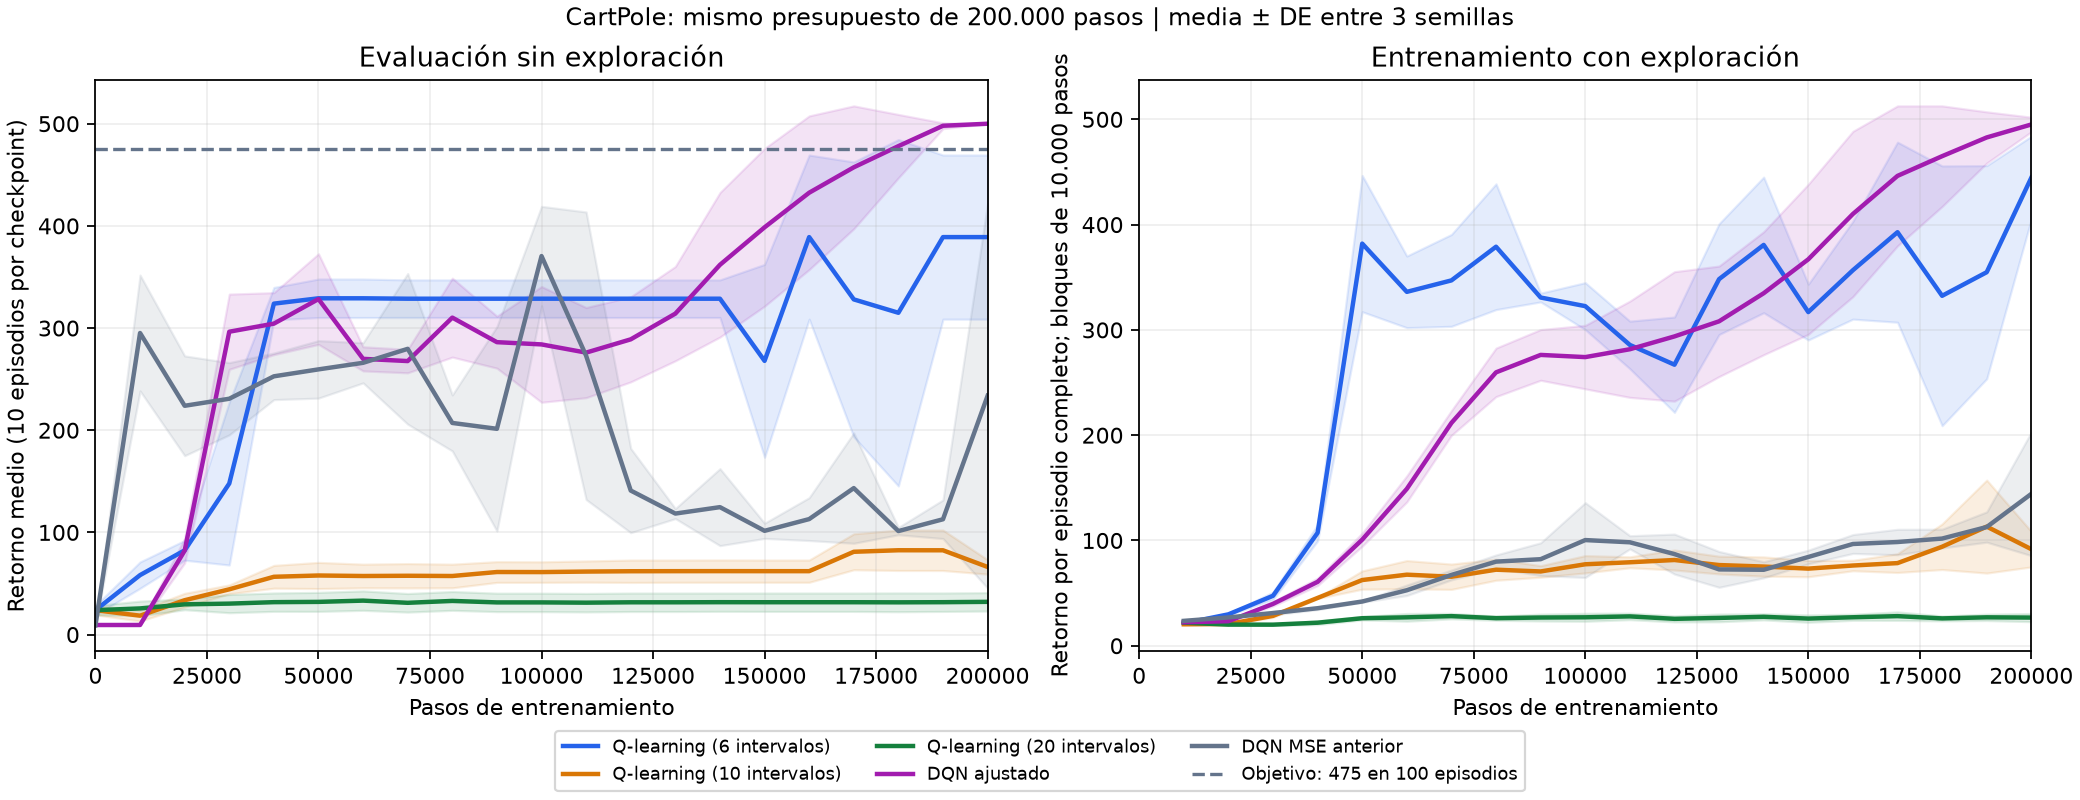

In [14]:
ACTUAL = actual()
print('Versión mostrada:', ACTUAL['description'])
filas = resumen()
display(Image(filename=str(ROOT / ACTUAL['comparison'] / 'tier1_comparacion.png')))

### Cómo leer la gráfica

- **Horizontal:** pasos de entrenamiento, no episodios.
- **Vertical izquierda:** recompensa de evaluación sin explorar. Más alto es mejor.
- **Bandas:** una desviación estándar entre semillas. Una banda amplia indica variación.
- **Panel derecho:** retorno durante entrenamiento, donde el agente todavía explora.
- La línea de 475 orienta; el éxito se confirma con **100 episodios**, no solo con 10.

Para mantener el tamaño de evaluación de la curva, al inicio y al final se muestran
los **primeros 10** de los 100 episodios guardados. La tabla final usa los **100**;
por eso el último punto de la curva puede diferir de su valor en la tabla.

### Antes y después de las mejoras
Conservamos los experimentos originales. No ocultamos las ejecuciones que fallaron ni
seleccionamos una semilla exitosa como si representara a todas.

In [15]:
anteriores = json.loads((ROOT / 'results/parte_15_mse_completo/comparacion/summary.json').read_text(encoding='utf-8'))
for fila in anteriores:
    print(f"Antes | {fila['method']}: {fila['final_mean_100_episodes']:.2f} ± {fila['std_across_seed_means']:.2f}")
print('\nDiscusión actual:')
display(Markdown((ROOT / ACTUAL['report']).read_text(encoding='utf-8')))

Antes | Q-learning (6 intervalos): 295.33 ± 109.06
Antes | Q-learning (10 intervalos): 359.70 ± 102.57
Antes | Q-learning (20 intervalos): 209.00 ± 39.25
Antes | DQN (MSE): 234.10 ± 188.02
Antes | DQN (Smooth L1 inicial): 48.47 ± 25.25

Discusión actual:


# Tier 1: notebook y mejora de CartPole

## Protocolo

Implementaciones propias de Q-learning y DQN estándar. Cada agente entrena 200000 pasos
con semillas 42, 43 y 44. Evaluación greedy separada cada 10000 pasos (10 episodios),
evaluación final de 100 episodios y confirmaciones de 100 si un control da ≥475.
Se entrega el modelo final; no se elige el mejor checkpoint ni se descartan semillas.
Las bandas son una desviación estándar entre las tres medias por semilla, no IC del 95%.
Las curvas usan los primeros 10 episodios también al inicio/final; las tablas finales usan 100.
El objetivo del enunciado es ≥475; se registra por separado el umbral declarado por Gymnasium.

## Resultados finales

| Método | Media ± DE | Retornos por semilla (42, 43, 44) | Semillas ≥475 | Tiempo de entrenamiento |
|---|---:|---|---:|---:|
| Q-learning (6 intervalos) | 414.48 ± 62.85 | 350.75, 500.00, 392.69 | 1/3 | 58.89 s |
| Q-learning (10 intervalos) | 89.09 ± 5.48 | 93.94, 81.43, 91.89 | 0/3 | 81.07 s |
| Q-learning (20 intervalos) | 26.28 ± 2.40 | 28.48, 22.94, 27.43 | 0/3 | 50.70 s |
| DQN ajustado | 498.60 ± 1.98 | 495.79, 500.00, 500.00 | 3/3 | 243.48 s |
| DQN MSE anterior | 234.10 ± 188.02 | 101.67, 100.63, 500.00 | 1/3 | 250.15 s |

Los tiempos excluyen evaluación y son mediciones de esta computadora; no son benchmarks universales.
No se ejecutaron entrenamientos simultáneos. Se realizaron tareas de edición y comprobación durante el trabajo.

## Verificación y nuevos inicios

Los 100 retornos finales de cada uno de los 12 modelos se reprodujeron exactamente al cargarlo.
Después se evaluaron 100 inicios nuevos por modelo, sin entrenar ni ajustar parámetros.
La muestra se fijó antes de observarla: semilla de evaluación 3000000+1000*semilla_entrenada.
Son nuevos inicios de la misma distribución, no nuevas semillas de entrenamiento.

| Método | Media nueva ± DE | Semillas ≥475 |
|---|---:|---:|
| Q-learning (6 intervalos) | 425.15 ± 54.01 | 1/3 |
| Q-learning (10 intervalos) | 90.32 ± 15.49 | 0/3 |
| Q-learning (20 intervalos) | 28.08 ± 0.87 | 0/3 |
| DQN ajustado | 499.00 ± 1.41 | 3/3 |

La mayor media tabular entre estas tres granularidades fue Q-learning (6 intervalos): 414.48. Esa selección se hace con la media de las tres semillas, no con un episodio.
Si una granularidad no alcanza 475, se informa como resultado negativo; no se reemplaza por otra semilla.

## Qué cambió y qué podemos concluir

- DQN conserva replay, target, epsilon-greedy, recompensa original y corrección de cortes temporales.
- Red: [4, 120, 84, 2]; tasa 0.00025; memoria 10000; lote 128; inicio 10000; ajuste cada 10 pasos.
- Target cada 500; pérdida MSE; epsilon hasta 0.05 en 100000 pasos.
- Configuración DQN inspirada en CleanRL, pero ejecutada con nuestro propio agente. Se mantienen 200000 pasos,
  frente a los 500000 del default de referencia. También difieren generadores aleatorios y clipping de gradiente.
- Tabular: alpha=0.1, gamma=0.99, epsilon final=0.01; límites inferiores=[-2.4, -0.75, -0.20943951023931956, -0.8726646259971648]; superiores=[2.4, 0.75, 0.20943951023931956, 0.8726646259971648].
- Se modificaron varios parámetros para buscar una configuración funcional. Esto no es una ablación controlada
  ni permite atribuir toda la mejora a un único cambio. El estudio controlado de Tier 2 sigue pendiente.
- Las semillas 42/43/44 se usaron durante el desarrollo: no constituyen un test independiente de selección.
  La evaluación nueva comprueba otros inicios, sin demostrar éxito universal ni eliminar esa limitación.
- Más intervalos no garantizan mejor aprendizaje: cambian la resolución y el número de casillas por visitar.
- El ajuste tabular no mejoró todas las granularidades: 10 y 20 intervalos empeoraron respecto al diseño anterior.
  Los rangos y la exploración cambiaron juntos, por lo que no aislamos una causa única de ese deterioro.
- Los experimentos anteriores permanecen íntegros: DQN MSE anterior=234.10±188.02; mejor tabular anterior=359.70±102.57.

## Pasos hasta el objetivo

Primer control confirmado de 100 episodios; no identifica el instante exacto de aprendizaje:

- Q-learning (6 intervalos): 42: not reached, 43: 160000, 44: not reached
- Q-learning (10 intervalos): 42: not reached, 43: not reached, 44: not reached
- Q-learning (20 intervalos): 42: not reached, 43: not reached, 44: not reached
- DQN ajustado: 42: 190000, 43: 160000, 44: 160000
- DQN MSE anterior: 42: not reached, 43: not reached, 44: 200000

## Diagnóstico de valores Q

Máximos finales en los 256 estados de diagnóstico de cada semilla: [102.08712005615234, 101.60016632080078, 101.17017364501953].
Con gamma=0.99 y recompensa ≤1 el retorno descontado verdadero no supera 100.
Persisten pequeñas sobreestimaciones incluso cuando la política alcanza el objetivo.
La muestra diagnóstica no entrena al agente ni demuestra corrección en todos los estados.
Este valor descontado es distinto del retorno de hasta 500 puntos por episodio.

## Reproducibilidad

Python 3.12.0; paquetes {'gymnasium': '1.4.0', 'numpy': '2.5.4', 'torch': '2.15.0+cpu'}; plataforma Windows-11-10.0.26200-SP0.
CPU AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD; 8 procesadores lógicos; PyTorch CPU, un hilo.
Parámetros editables en configs/tier1_mejorado.json y notebook Tier1_Explicado.ipynb.
Los comandos están en REPRODUCIR_TIER1.md. El notebook muestra el código real y los archivos guardados.

## Referencias y alcance

- CleanRL DQN: https://docs.cleanrl.dev/rl-algorithms/dqn/
- Configuración de referencia: https://github.com/vwxyzjn/cleanrl/blob/master/cleanrl/dqn.py
- Gymnasium CartPole: https://gymnasium.farama.org/environments/classic_control/cart_pole/

Este bloque corresponde a Tier 1. Faltan Tier 2, Tier 3 para la pareja, análisis teórico,
integración del artículo final y preparación de defensa. El notebook no sustituye el paper.


### Ver los parámetros exactos de un modelo

Escoge una semilla en esta celda. El archivo corresponde a un entrenamiento concreto;
la evaluación adicional de nuevos inicios se documenta en la discusión.

In [16]:
SEMILLA = 42  # Opciones: 42, 43, 44. No cambiar para buscar solo el mejor resultado.
CARPETA_DQN = ROOT / ACTUAL['dqn_root'] / f'seed_{SEMILLA}'
config_guardada = json.loads((CARPETA_DQN / 'config.json').read_text(encoding='utf-8'))
print(json.dumps(config_guardada, indent=2, ensure_ascii=False))
print('Resumen:', json.loads((CARPETA_DQN / 'summary.json').read_text(encoding='utf-8')))

{
  "environment": "CartPole-v1",
  "algorithm": "vanilla DQN propio",
  "seed": 42,
  "training_steps": 200000,
  "architecture": [
    4,
    120,
    84,
    2
  ],
  "learning_rate": 0.00025,
  "gamma": 0.99,
  "buffer_size": 10000,
  "batch_size": 128,
  "learning_starts": 10000,
  "train_every": 10,
  "target_sync_every_environment_steps": 500,
  "optimizer": "Adam",
  "loss": "MSE",
  "gradient_norm_limit": 10,
  "epsilon_start": 1,
  "epsilon_end": 0.05,
  "decay_fraction": 0.5,
  "epsilon_decay_steps": 100000,
  "q_probe": {
    "states": 256,
    "policy": "random",
    "seed": 90042,
    "used_for_training": false
  },
  "eval_every": 10000,
  "periodic_eval_episodes": 10,
  "initial_final_eval_episodes": 100,
  "success_threshold": 475,
  "threshold_confirmation": "100 episodios cuando el control de 10 obtiene >=475",
  "eval_reset_seeds": "seed + 10000 + episode",
  "eval_action_rng_seed": 20042,
  "replay_seed": 30042,
  "python": "3.12.0",
  "platform": "Windows-11-10.0.

### Volver a comprobar los 100 episodios del modelo guardado

No se actualizan pesos. Se vuelven a usar las condiciones documentadas para comprobar
reproducibilidad; esto **no equivale a entrenar otra semilla independiente**.

In [17]:
REEVALUAR = False
if REEVALUAR:
    retornos = evaluar_guardado(CARPETA_DQN, episodes=100)
    print('Media:', np.mean(retornos), '| ¿≥475?:', np.mean(retornos) >= 475)
else:
    print('Reevaluación opcional desactivada; la tabla anterior usa evaluaciones ya guardadas.')

Reevaluación opcional desactivada; la tabla anterior usa evaluaciones ya guardadas.


## 7. Ver el carrito dentro del notebook

Selecciona `AGENTE='dqn'` o `'tabular'` y una semilla. Se reproduce el primer episodio
de su evaluación. **No aprende durante esta demostración.** La animación incluye
controles de reproducción; el resultado de un episodio no sustituye la media de 100.

Activar `VER_CARRITO` genera la animación. También puedes ejecutar
`demostrar(carpeta, inline=False)` para abrir una ventana independiente.

In [18]:
VER_CARRITO = False
AGENTE = 'dqn'        # 'dqn' o 'tabular'
SEMILLA_DEMO = 42     # 42, 43 o 44
BINS_DEMO = ACTUAL.get('tabular_bins', 10)  # Puedes cambiarlo a 6, 10 o 20.
if VER_CARRITO:
    if AGENTE not in ('dqn', 'tabular'):
        raise ValueError('Escoge dqn o tabular')
    base = (ROOT / ACTUAL['dqn_root']) if AGENTE == 'dqn' else (ROOT / ACTUAL['tabular_root'] / f'bins_{BINS_DEMO}')
    carpeta = base / f'seed_{SEMILLA_DEMO}'
    demostrar(carpeta, episodes=1, inline=True)
else:
    print('Cambia VER_CARRITO a True y ejecuta esta celda para ver la animación.')

Cambia VER_CARRITO a True y ejecuta esta celda para ver la animación.


## 8. Qué debemos poder explicar los dos

1. ¿Qué representan las cuatro observaciones y los dos valores Q?
2. ¿Qué información perdemos al discretizar? ¿Por qué más intervalos no siempre ayudan?
3. ¿Qué hacen alpha, gamma y epsilon? ¿Por qué evaluar con epsilon=0?
4. ¿Para qué sirven replay y target? ¿Qué cambia con terminated y truncated?
5. ¿Por qué repetimos el entrenamiento con tres semillas y usamos el mismo presupuesto?
6. ¿Qué diferencia existe entre un episodio de 500 y una media ≥475 en 100 episodios?
7. ¿Qué mejoró y qué limitaciones siguen presentes?

**Archivos:** `agents/` algoritmos · `envs/` discretización · `experiments/` ejecución
· `configs/` parámetros · `results/` evidencias · `report/` discusión y uso de IA.

El notebook cubre Tier 1. Siguen pendientes Tier 2, Tier 3 para la pareja, el análisis
teórico, el artículo final y preparar la defensa. El docente exige que ambos entiendan
todo el código, incluyendo lo desarrollado con ayuda de IA.

**Referencias:** [Enunciado local](Project_01_Reinforcement_Learning_DQN.md),
[Gymnasium](https://gymnasium.farama.org/environments/classic_control/cart_pole/),
[CleanRL DQN](https://docs.cleanrl.dev/rl-algorithms/dqn/).
El agente entregado sigue siendo nuestra implementación.